# Difference order and controlled smoothness

The order $d$ defines which discrete derivative is penalized. For $d=1$, the infinite-penalty limit is constant (when $\mu=0$); for $d=2$, it is linear; for $d=3$, it is quadratic. These are theoretical limits of penalized least squares, not learned forecast models.

In [1]:
import awesomefigures as af
from matplotlib_inline.backend_inline import set_matplotlib_formats

# Publication styling only; numerical estimates and metrics are unchanged.
af.set_style("elegante", font="DejaVu Sans", use_tex=False,
             palette="okabe-ito", rasterize=False)
set_matplotlib_formats("svg", "png")

from trendestimation._docs_style import apply_documentation_figure_style
apply_documentation_figure_style()


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from trendestimation import TrendSmoother, difference_matrix

rng = np.random.default_rng(19)
t = np.linspace(-1, 1, 80)
y = 2 + 1.2 * t + 0.9 * t**2 + rng.normal(0, 0.25, t.size)

## Compare orders at equal normalized smoothness

Penalty values are **not directly comparable across orders**. Instead, ask each solver for the penalty that attains the same normalized smoothness level.

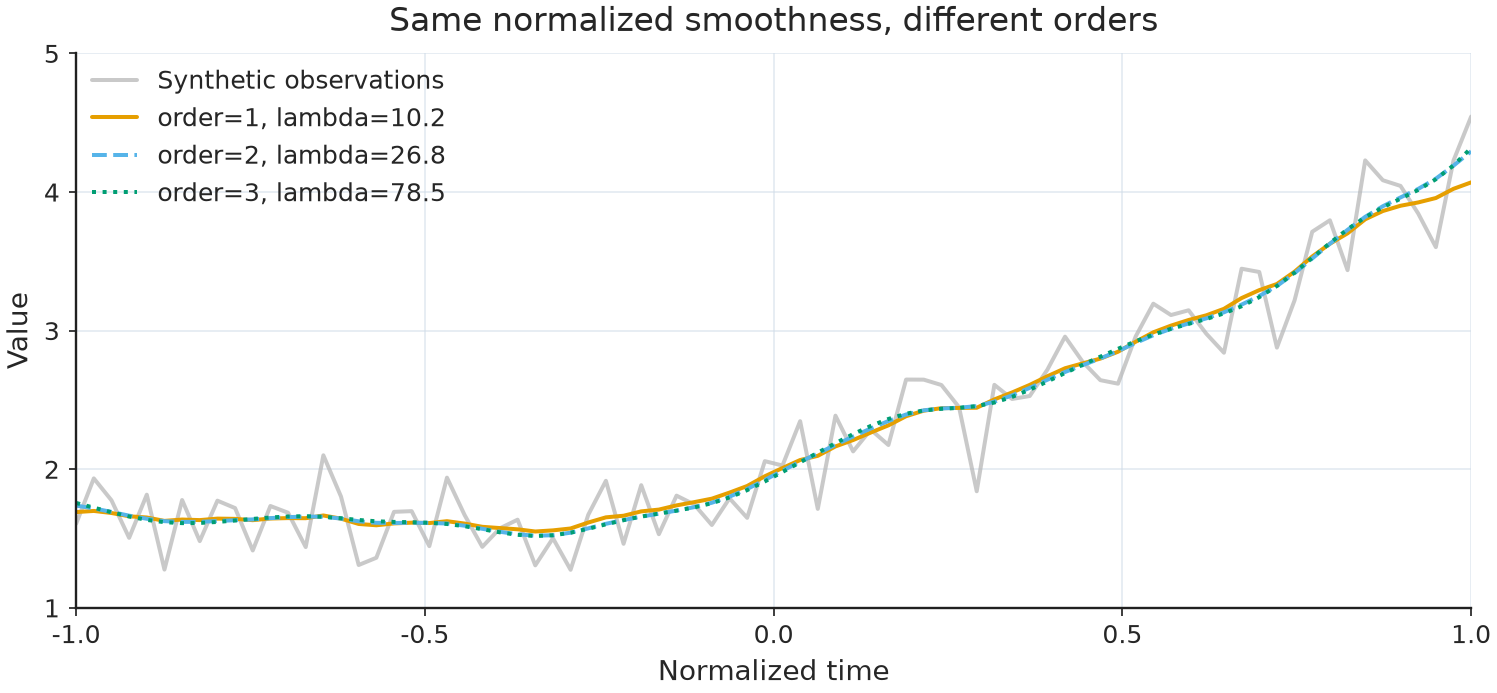

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t, y, '-', color='0.7', alpha=0.7, label='Synthetic observations')
for order in (1, 2, 3):
    solver = TrendSmoother(y.size, order=order)
    penalty = solver.lambda_for_smoothness(0.85)
    fit = solver.fit(y, lambda_=penalty, mu=0.0)
    ax.plot(t, fit.trend, label=f"order={order}, lambda={penalty:.3g}")
ax.set(xlabel='Normalized time', ylabel='Value', title='Same normalized smoothness, different orders')
ax.legend()
plt.show()

## Inspect the exact infinite-penalty limit

The library computes the nullspace projection directly at $\lambda=\infty$. This avoids choosing an arbitrarily large finite penalty and suffering avoidable numerical conditioning problems.

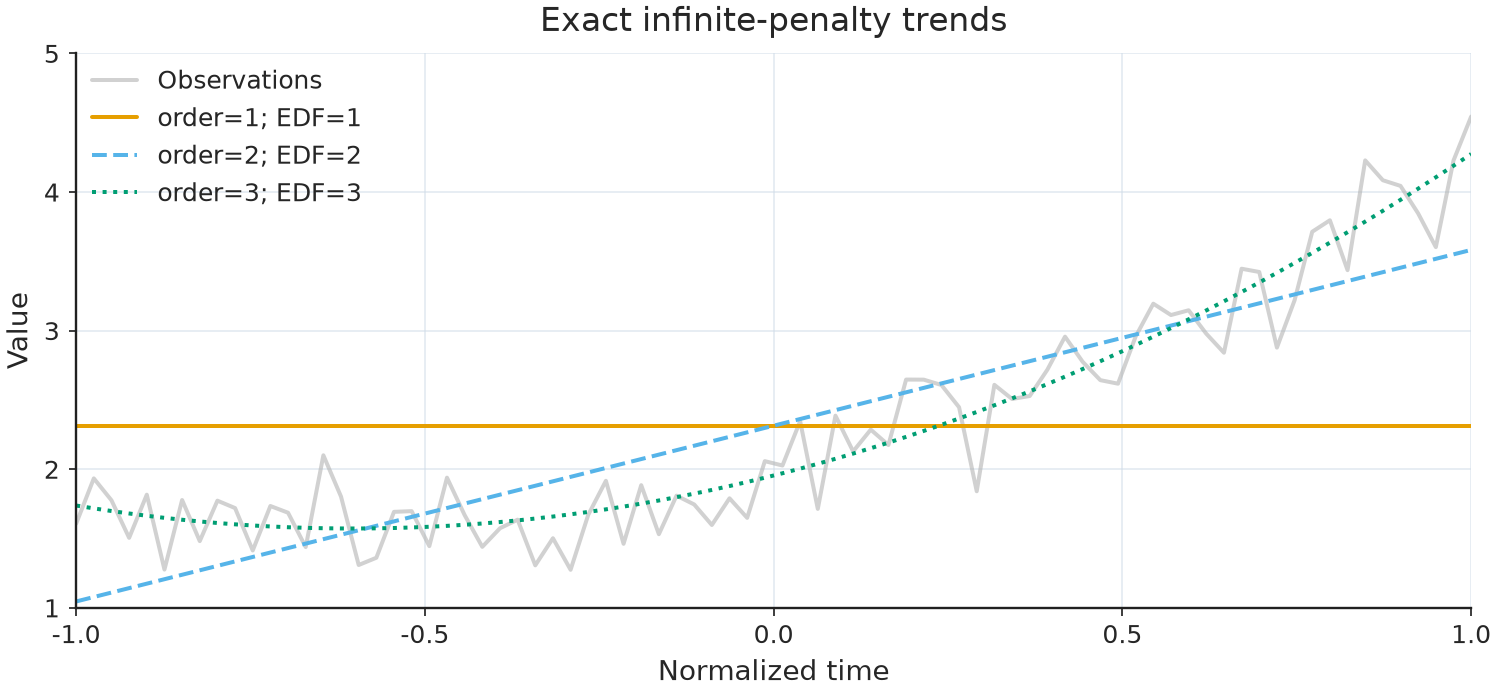

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t, y, '-', color='0.7', alpha=0.6, label='Observations')
for order in (1, 2, 3):
    solver = TrendSmoother(y.size, order=order)
    limit = solver.fit(y, lambda_=np.inf, mu=0.0)
    ax.plot(t, limit.trend, label=f"order={order}; EDF={limit.edf_conditional:.0f}")
ax.set(xlabel='Normalized time', ylabel='Value', title='Exact infinite-penalty trends')
ax.legend()
plt.show()

## Nonzero reference differences

Guerrero's formulation allows a nonzero reference mean $\mu$ for the differences. The mode `mu="data"` estimates this scalar from the observed differences; reported EDF remains **conditional** on that selected mean.

In [5]:
solver = TrendSmoother(y.size, order=1)
fit = solver.fit(y, lambda_=20.0, mu="data")
print(f"Estimated observed-difference mean: {fit.mu:.4g}")
print(f"Difference-matrix shape: {difference_matrix(len(y), 1).shape}")

Estimated observed-difference mean: 0.03718
Difference-matrix shape: (79, 80)


## Side-by-side penalty and normalized-smoothness coordinates

The following reproducible figures show the **same PLS estimator and fixed-mean CV/GCV/AICc/BIC scores** plotted against both the raw penalty $\lambda$ and normalized trace smoothness $S(\lambda)$. Both panels mark the same lowest-scoring **matched-grid** candidate. The final small timing chart runs the public GCV selector once in each coordinate. It is **illustrative only**, since the two default searches inspect different grids; controlled multi-seed timings belong to `benchmarks/criterion_coordinate_matrix.py` and `benchmarks/public_coordinate_optimizer_benchmark.py`.

Paired penalty and smoothness: last 60 points of the notebook series; n=60, d=2, mu=0


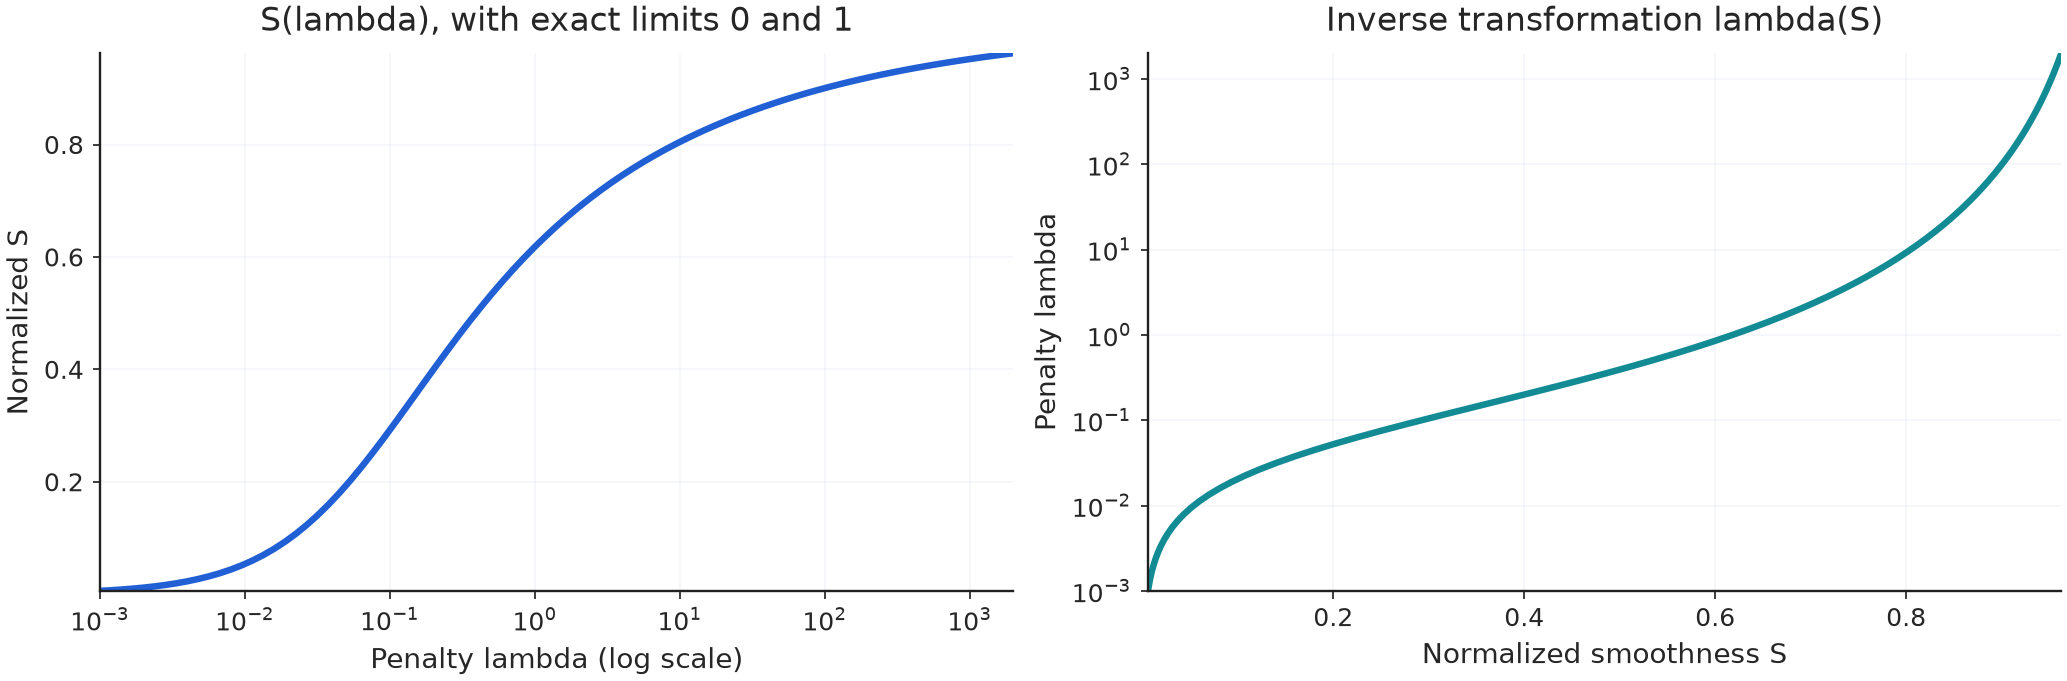

CV: selected lambda=1002.3, S=0.95205, score=0.0643152
GCV: selected lambda=843.27, S=0.94915, score=0.0634375
AICC: selected lambda=1191.2, S=0.95482, score=-2.72556
BIC: selected lambda=0.001, S=0.00593, score=-8.54216


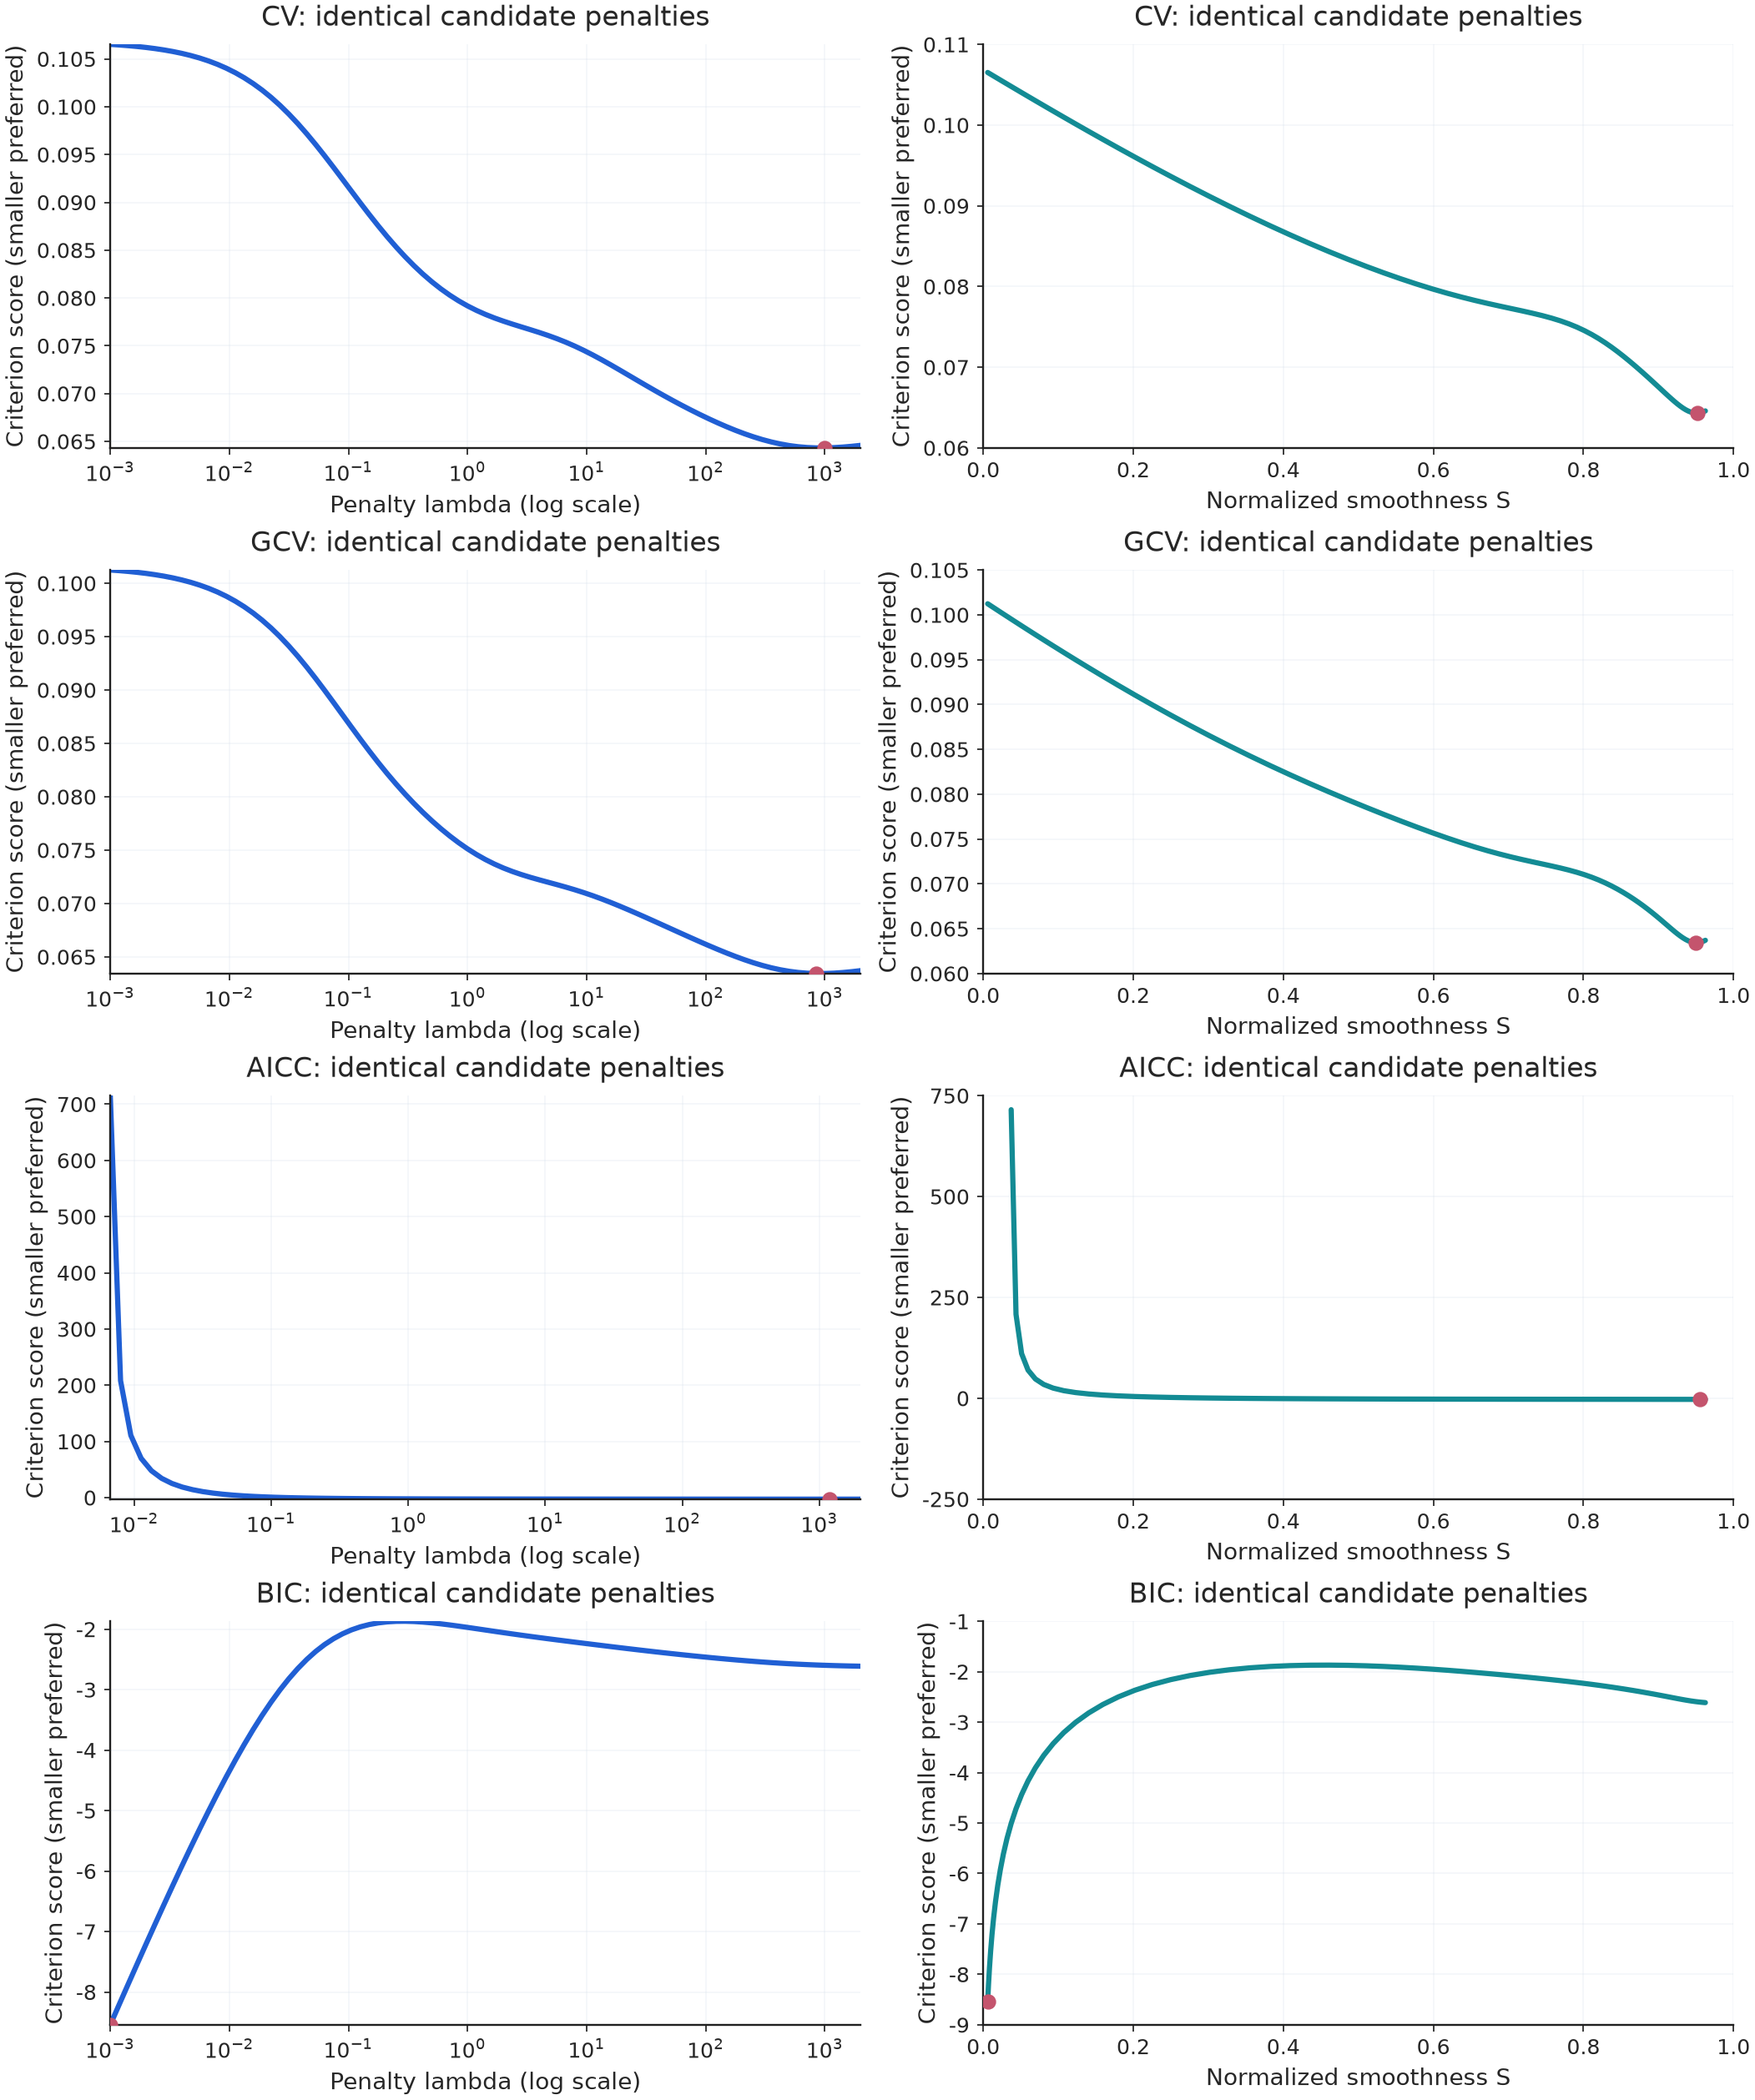

GCV lambda auto-search: 1.915 ms, lambda=977.29, S=0.95164, score=0.0634376, candidates=122
GCV smoothness auto-search: 26.548 ms, lambda=886.17, S=0.95000, score=0.0634348, candidates=125


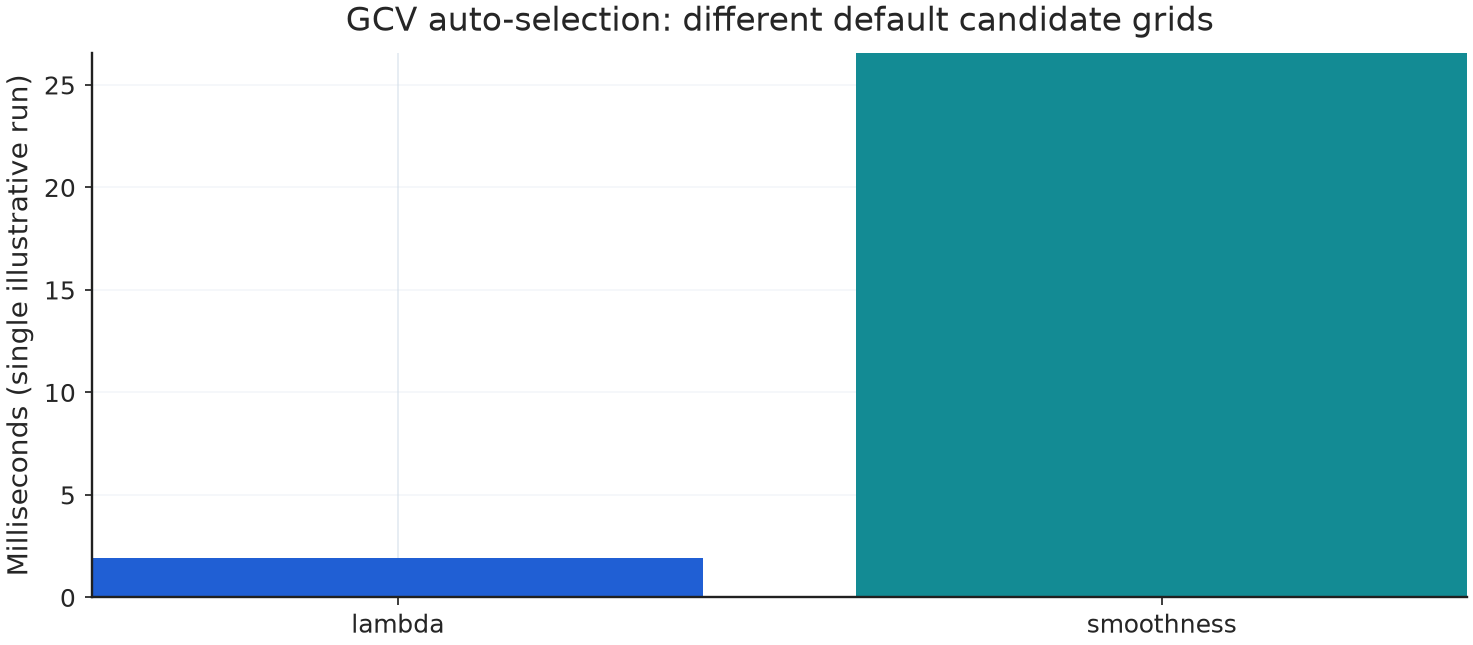

Timing is descriptive, not a controlled speed ranking. See the factorial and public API benchmarks for paired repetitions.


In [6]:
from trendestimation._docs_coordinates import show_dual_coordinate_gallery

# Reuse notebook data when present; otherwise use a clearly labeled seeded example.
_coordinate_series = next((globals()[name] for name in
                           ("history", "y", "observed", "series")
                           if name in globals()), None)
show_dual_coordinate_gallery(_coordinate_series, order=2, mu=0.0)
